# 02 · Datos de ÁUREA: coherencia con ms-analítica

**Qué hace:** lee la serie de ventas de ÁUREA con el mismo GET firmado que usará ms-pronóstico, la valida con `rc_pronostico`, comprueba que la regla de respaldo detecta los cierres, compara los feriados de la librería `holidays` con los del generador y mide cuánto ruido hay entre lo vendido y la demanda verdadera.

**Decisiones que aplica:** D-23 (coherencia de la entrada), D-05 (cierres por regla de respaldo), D-01 y D-21 (ÁUREA es sintético y se declara así), D-19 (credenciales en `.env`).

**Requiere Docker encendido** con `restaurantcloudIA_analitica` en marcha, y `model-ia/.env` con `ANALITICA_URL`, `ANALITICA_SECRETO`, `EMPRESA_AUREA` y `LOCAL_AUREA`.

**Deja:** `salidas/aurea/historial.parquet`, `calendario.json`, `productos.json`, `verdad.parquet` y figuras en `resultados/exploracion/`.

In [1]:
# Parámetros
import os, json, time, hmac, hashlib, subprocess
from datetime import date, timedelta
from pathlib import Path
from dotenv import load_dotenv

RAIZ = Path.cwd().parent if Path.cwd().name == "cuadernos" else Path.cwd()
load_dotenv(RAIZ / ".env")
URL, SECRETO = os.environ["ANALITICA_URL"], os.environ["ANALITICA_SECRETO"]
EMPRESA, LOCAL = os.environ["EMPRESA_AUREA"], os.environ["LOCAL_AUREA"]
CONTENEDOR = "restaurantcloudIA_analitica"
DESDE, HASTA = date(2024, 11, 18), date(2026, 11, 17)   # 24 meses de aurea_v1, semilla 2026
MAX_DIAS = 730                                          # app/dominio/series.py
SALIDA = RAIZ / "salidas" / "aurea"
FIGURAS = RAIZ / "resultados" / "exploracion"
SALIDA.mkdir(parents=True, exist_ok=True); FIGURAS.mkdir(parents=True, exist_ok=True)

## 1. Cliente firmado
`X-Firma = HMAC-SHA256("{X-Timestamp}.{cadena de consulta}")` con el secreto del servicio (`doc-2u/servicios/README.md`, sección 2; mismo cálculo que `calcular_firma` en `app/soporte/firma.py`, sin importarlo). La firma cubre la consulta tal como se envía. Si el rango pasa de 730 días (ambos extremos incluidos), se pide por tramos.

In [2]:
import httpx
import numpy as np, pandas as pd

def firmar(consulta: str, secreto: str = SECRETO, ts: str | None = None) -> dict:
    ts = ts or str(int(time.time()))
    firma = hmac.new(secreto.encode(), f"{ts}.{consulta}".encode(), hashlib.sha256).hexdigest()
    return {"X-Timestamp": ts, "X-Firma": firma}

def pedir(desde: date, hasta: date) -> httpx.Response:
    consulta = f"empresa_id={EMPRESA}&local_id={LOCAL}&desde={desde}&hasta={hasta}"
    return httpx.get(f"{URL}/interno/series/ventas-diarias?{consulta}", headers=firmar(consulta), timeout=60)

def tramos(desde: date, hasta: date, maximo: int = MAX_DIAS):
    while desde <= hasta:
        fin = min(desde + timedelta(days=maximo - 1), hasta)
        yield desde, fin
        desde = fin + timedelta(days=1)

def leer_serie(desde: date, hasta: date) -> dict:
    productos, ultimo = {}, None
    for a, b in tramos(desde, hasta):
        r = pedir(a, b); r.raise_for_status()
        datos = r.json()["datos"]; ultimo = datos["ultimo_evento_en"]
        for p in datos["productos"]:
            e = productos.setdefault(p["producto_id"], {**{k: p[k] for k in ("nombre", "categoria_nombre", "primera_venta")}, "serie": []})
            e["serie"] += p["serie"]
    return {"productos": productos, "ultimo_evento_en": ultimo}

# Comprobaciones del protocolo: sin firma o con firma ajena, rechaza; más de 730 días, rechaza.
consulta = f"empresa_id={EMPRESA}&local_id={LOCAL}&desde={DESDE}&hasta={HASTA}"
sin_firma = httpx.get(f"{URL}/interno/series/ventas-diarias?{consulta}").status_code
firma_ajena = httpx.get(f"{URL}/interno/series/ventas-diarias?{consulta}", headers=firmar(consulta, "otro-secreto")).status_code
demasiado = pedir(DESDE - timedelta(days=1), HASTA)
print("sin firma:", sin_firma, "| firma ajena:", firma_ajena, "| 731 días:", demasiado.status_code, demasiado.json()["errores"][0]["codigo"] if demasiado.status_code != 200 else "")
print("tramos de", (HASTA - DESDE).days + 1, "días:", [(str(a), str(b)) for a, b in tramos(DESDE, HASTA)])
print("tramos de 1500 días (ejemplo):", [(str(a), str(b)) for a, b in tramos(date(2024, 1, 1), date(2028, 1, 9))])

sin firma: 401 | firma ajena: 401 | 731 días: 422 ERR_RANGO_INVALIDO
tramos de 730 días: [('2024-11-18', '2026-11-17')]
tramos de 1500 días (ejemplo): [('2024-01-01', '2025-12-30'), ('2025-12-31', '2027-12-30'), ('2027-12-31', '2028-01-09')]


## 2. Serie de ÁUREA al historial largo del contrato

In [3]:
from rc_pronostico.contrato import validar_historial

serie = leer_serie(DESDE, HASTA)
filas = [(pid, p["serie"][i]["fecha"], p["serie"][i]["unidades"]) for pid, p in serie["productos"].items() for i in range(len(p["serie"]))]
largo = pd.DataFrame(filas, columns=["producto_id", "fecha", "unidades"])
historial = validar_historial(largo, hoy=pd.Timestamp.today())     # rechaza si incluye hoy
nombres = {pid: {"nombre": p["nombre"], "categoria": p["categoria_nombre"], "primera_venta": p["primera_venta"]} for pid, p in serie["productos"].items()}
print(historial.shape, historial.producto_id.nunique(), "platos |", historial.fecha.min().date(), "→", historial.fecha.max().date())
pd.DataFrame(nombres).T.sort_values(["categoria", "nombre"])

(14600, 3) 20 platos | 2024-11-18 → 2026-11-17


,nombre,categoria,primera_venta
00000000-0000-4000-8000-000000000614,Agua Mineral 625ml,Bebidas,2024-11-18
00000000-0000-4000-8000-000000000613,Cerveza Cusqueña,Bebidas,2024-11-18
00000000-0000-4000-8000-000000000611,Chicha Morada (jarra),Bebidas,2024-11-18
00000000-0000-4000-8000-000000000433,Inca Kola 500ml,Bebidas,2024-11-18
00000000-0000-4000-8000-000000000612,Limonada Frozen,Bebidas,2024-11-18
00000000-0000-4000-8000-000000000435,Causa Limeña de Pollo,Entradas,2024-11-18
00000000-0000-4000-8000-000000000431,Ceviche Clásico,Entradas,2024-11-18
00000000-0000-4000-8000-000000000604,Ceviche Mixto,Entradas,2024-11-18
00000000-0000-4000-8000-000000000603,Choritos a la Chalaca,Entradas,2024-11-18
00000000-0000-4000-8000-000000000601,Leche de Tigre,Entradas,2024-11-18


## 3. Cierres: regla de respaldo (D-05)
ms-analítica no entrega `dias_cerrados`. Se aplica la regla: cerrado el día en que el local entero vendió 0. En ÁUREA debe dar exactamente el 25/12 y el 01/01 de cada año del rango.

In [4]:
from rc_pronostico.calendario import dias_cerrados
cerrados = dias_cerrados(historial, None)
esperados = pd.DatetimeIndex(["2024-12-25", "2025-01-01", "2025-12-25", "2026-01-01"])
print([d.strftime("%Y-%m-%d (%a)") for d in cerrados])
print("Coincide exactamente con 25/12 y 01/01:", cerrados.equals(esperados))
total_dia = historial.groupby("fecha").unidades.sum()
print("Menor venta total en un día abierto:", int(total_dia.drop(cerrados).min()), "unidades")

['2024-12-25 (Wed)', '2025-01-01 (Wed)', '2025-12-25 (Thu)', '2026-01-01 (Thu)']
Coincide exactamente con 25/12 y 01/01: True
Menor venta total en un día abierto: 137 unidades


## 4. Feriados: `holidays` frente al generador (D-23)
En producción el calendario del local sale de la librería `holidays` (Perú). El generador de ÁUREA tiene su propia lista (`app/sinteticos/feriados.py`). Se lee directamente del contenedor, no copiada, y se compara año por año; cualquier diferencia se documenta, porque el experimento de control mediría también esa diferencia.

In [5]:
import holidays

script = '''
import json
from app.sinteticos.feriados import feriados_peru, eventos_de_demanda
anios = (2024, 2025, 2026)
print(json.dumps({"feriados": {str(a): {str(d): n for d, n in feriados_peru(a).items()} for a in anios},
                  "eventos": {str(a): {str(d): n for d, n in eventos_de_demanda(a).items()} for a in anios}}, ensure_ascii=False))
'''
salida = subprocess.run(["docker", "exec", CONTENEDOR, "python", "-c", script], capture_output=True, check=True, encoding="utf-8").stdout
generador = json.loads(salida)
(SALIDA / "feriados_generador.json").write_text(json.dumps(generador, indent=1, ensure_ascii=False), encoding="utf-8")

lib = holidays.Peru(years=range(2024, 2028), language="es")
filas = []
for anio in ("2024", "2025", "2026"):
    g = {d: n for d, n in generador["feriados"][anio].items()}
    l = {str(d): n for d, n in lib.items() if str(d).startswith(anio)}
    for d in sorted(set(g) | set(l)):
        filas.append({"año": anio, "fecha": d, "solo_en": "ambos" if d in g and d in l else ("generador" if d in g else "holidays"),
                      "generador": g.get(d, ""), "holidays": l.get(d, "")})
cmp = pd.DataFrame(filas)
resumen = cmp.groupby(["año", "solo_en"]).size().unstack(fill_value=0)
print(resumen)
cmp[cmp.solo_en != "ambos"]

solo_en  ambos  holidays
año                     
2024        14         3
2025        14         3
2026        14         3


,año,fecha,solo_en,generador,holidays
3,2024,2024-03-31,holidays,,Domingo de Resurrección
5,2024,2024-06-07,holidays,,Batalla de Arica y Día de la Bandera
7,2024,2024-07-23,holidays,,Día de la Fuerza Aérea del Perú
20,2025,2025-04-20,holidays,,Domingo de Resurrección
22,2025,2025-06-07,holidays,,Batalla de Arica y Día de la Bandera
24,2025,2025-07-23,holidays,,Día de la Fuerza Aérea del Perú
37,2026,2026-04-05,holidays,,Domingo de Resurrección
39,2026,2026-06-07,holidays,,Batalla de Arica y Día de la Bandera
41,2026,2026-07-23,holidays,,Día de la Fuerza Aérea del Perú


Las diferencias se leen así: **«solo holidays»** son feriados que la librería conoce y el generador no (el modelo los marcará como feriado, pero ÁUREA no cambió su demanda esos días). **«Solo generador»** serían feriados que el generador aplica y el modelo no recibiría marcados. Las fechas que mueven la demanda y no son feriado (San Valentín, Día de la Madre, Nochebuena, Fin de Año…) las usa el generador y el modelo no las conoce: es una limitación del experimento de control, no un error (D-23).

In [6]:
# Calendario de ÁUREA: cierres detectados por la regla de respaldo y feriados de la librería
# (años del rango y el siguiente, para los días objetivo que caen después del último dato)
fer = sorted(str(d) for d, _ in lib.items() if d.year in (2024, 2025, 2026, 2027))
calendario = {"dias_cerrados": [d.strftime("%Y-%m-%d") for d in cerrados],
              "origen_dias_cerrados": "regla_de_respaldo_D-05",
              "feriados": fer, "origen_feriados": "holidays.Peru"}
print(len(fer), "feriados 2024-2027 |", int((cmp.solo_en == "holidays").sum()), "solo en holidays,", int((cmp.solo_en == "generador").sum()), "solo en el generador (2024-2026)")

68 feriados 2024-2027 | 9 solo en holidays, 0 solo en el generador (2024-2026)


## 5. `ultimo_evento_en` no es fiable
En ÁUREA vale la hora de la carga sintética, no la de la última venta.

In [7]:
ultimo = pd.Timestamp(serie["ultimo_evento_en"])
print("ultimo_evento_en:", ultimo, "| última jornada de la serie:", historial.fecha.max().date())
evento_posterior = ultimo.date() > historial.fecha.max().date()
meta = {"ultimo_evento_en": serie["ultimo_evento_en"], "ultimo_evento_en_confiable": False,
        "motivo": "en la base de desarrollo vale la hora de la carga sintetica"}

ultimo_evento_en: 2026-11-18 23:15:02-05:00 | última jornada de la serie: 2026-11-17


## 6. Demanda verdadera (`--verdad`)
El generador guarda la demanda **esperada** por plato y día. Se copia del contenedor; si ya no está, se vuelve a generar con la misma semilla y rango (idempotente, unos 4 minutos).

In [8]:
destino = SALIDA / "verdad.csv"
copia = subprocess.run(["docker", "cp", f"{CONTENEDOR}:/tmp/verdad.csv", str(destino)], capture_output=True, encoding="utf-8")
if copia.returncode != 0:
    # No ejercitado en esta corrida: el archivo estaba en el contenedor. Mismo procedimiento que el README de ms-analítica.
    carta = subprocess.run(["docker", "exec", "restaurantcloudIA_api", "php", "artisan", "carta:exportar", LOCAL],
                           capture_output=True, check=True).stdout
    subprocess.run(["docker", "exec", "-i", CONTENEDOR, "python", "-m", "app.sinteticos", "generar", "--carta", "-",
                    "--perfil", "aurea_v1", "--semilla", "2026", "--meses", "24", "--verdad", "/tmp/verdad.csv"],
                   input=carta, check=True)
    subprocess.run(["docker", "cp", f"{CONTENEDOR}:/tmp/verdad.csv", str(destino)], check=True)

verdad = pd.read_csv(destino, parse_dates=["fecha"]).rename(columns={"unidades_esperadas": "esperadas"})
verdad.to_parquet(SALIDA / "verdad.parquet", index=False)
destino.unlink()
print(verdad.shape, verdad.fecha.min().date(), "→", verdad.fecha.max().date())
verdad.head(3)

(14600, 3) 2024-11-18 → 2026-11-17


,fecha,producto_id,esperadas
0,2024-11-18,00000000-0000-4000-8000-000000000435,6.5333
1,2024-11-18,00000000-0000-4000-8000-000000000431,17.4221
2,2024-11-18,00000000-0000-4000-8000-000000000604,15.2444


In [9]:
# Piso de ruido: error de lo vendido frente a lo esperado, solo en días abiertos.
# Ningún modelo puede bajar de aquí si predijera exactamente la demanda esperada.
m = historial.merge(verdad, on=["producto_id", "fecha"], how="inner")
m_abiertos = m[~m.fecha.isin(cerrados)]
piso = m_abiertos.assign(ae=(m_abiertos.unidades - m_abiertos.esperadas).abs()).groupby("producto_id").agg(
    media_vendida=("unidades", "mean"), MAE_piso=("ae", "mean"), dias_cero=("unidades", lambda s: int((s == 0).sum())))
piso["WAPE_piso"] = piso.MAE_piso / piso.media_vendida
piso.insert(0, "plato", [nombres[p]["nombre"] for p in piso.index])
print("Filas verdad vs historial:", len(m), "de", len(historial))
print(f"Piso de ruido global: MAE {m_abiertos.assign(ae=(m_abiertos.unidades - m_abiertos.esperadas).abs()).ae.mean():.3f}")
piso.round(3).sort_values("media_vendida", ascending=False)

Filas verdad vs historial: 14600 de 14600
Piso de ruido global: MAE 4.964


,plato,media_vendida,MAE_piso,dias_cero,WAPE_piso
producto_id,,,,,
00000000-0000-4000-8000-000000000432,Lomo Saltado Criollo,35.167,7.532,0,0.214
00000000-0000-4000-8000-000000000613,Cerveza Cusqueña,34.433,7.643,0,0.222
00000000-0000-4000-8000-000000000433,Inca Kola 500ml,32.623,7.008,0,0.215
00000000-0000-4000-8000-000000000612,Limonada Frozen,32.136,6.806,0,0.212
00000000-0000-4000-8000-000000000606,Arroz con Mariscos,30.113,6.496,0,0.216
00000000-0000-4000-8000-000000000607,Jalea Mixta,27.880,6.288,0,0.226
00000000-0000-4000-8000-000000000611,Chicha Morada (jarra),26.960,5.958,0,0.221
00000000-0000-4000-8000-000000000431,Ceviche Clásico,23.994,5.594,0,0.233
00000000-0000-4000-8000-000000000608,Chaufa de Mariscos,22.051,5.192,0,0.235


In [10]:
# ¿Cuánto espacio hay sobre el piso? Ingenuo estacional a h=2 en el último año de la serie
from rc_pronostico.variables import codigos_producto, filas_entrenamiento
from rc_pronostico.baselines import baselines
cal = {"dias_cerrados": calendario["dias_cerrados"], "feriados": calendario["feriados"]}
ent = filas_entrenamiento(historial, cal, historial.fecha.max(), codigos_producto(historial))
ent = ent[(ent.h == 2) & (ent.fecha_objetivo > historial.fecha.max() - pd.Timedelta(days=365))]
bl = baselines(historial, cal, ent)
mae_ing = (ent.y - bl.ingenuo).abs().mean(); mae_med4 = (ent.y - bl.media_mismo_dia).abs().mean()
piso_u = ent.merge(verdad, left_on=["producto_id", "fecha_objetivo"], right_on=["producto_id", "fecha"])
mae_piso = (piso_u.y - piso_u.esperadas).abs().mean()
pd.Series({"piso de ruido (esperada)": mae_piso, "media del mismo día (4)": mae_med4, "ingenuo estacional": mae_ing}).round(3)

piso de ruido (esperada)    5.086
media del mismo día (4)     5.894
ingenuo estacional          7.351
dtype: float64

## 7. Exploración
Mismos gráficos que en el 01, con los nombres de los platos.

In [11]:
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
hist_n = historial.assign(plato=historial.producto_id.map(lambda p: nombres[p]["nombre"]))
abiertos = hist_n[~hist_n.fecha.isin(cerrados)]
escala = abiertos.groupby("plato").unidades.agg(media="mean", mediana="median", p90=lambda s: s.quantile(.9), maximo="max", dias_en_cero=lambda s: int((s == 0).sum()))
escala.round(2).sort_values("media", ascending=False)

,media,mediana,p90,maximo,dias_en_cero
plato,,,,,
Lomo Saltado Criollo,35.17,34.0,54.0,98,0
Cerveza Cusqueña,34.43,31.5,56.0,105,0
Inca Kola 500ml,32.62,30.0,54.0,117,0
Limonada Frozen,32.14,29.0,52.5,104,0
Arroz con Mariscos,30.11,28.0,46.0,89,0
Jalea Mixta,27.88,27.0,44.0,77,0
Chicha Morada (jarra),26.96,25.0,44.0,94,0
Ceviche Clásico,23.99,22.0,40.0,77,0
Chaufa de Mariscos,22.05,21.0,34.0,56,0


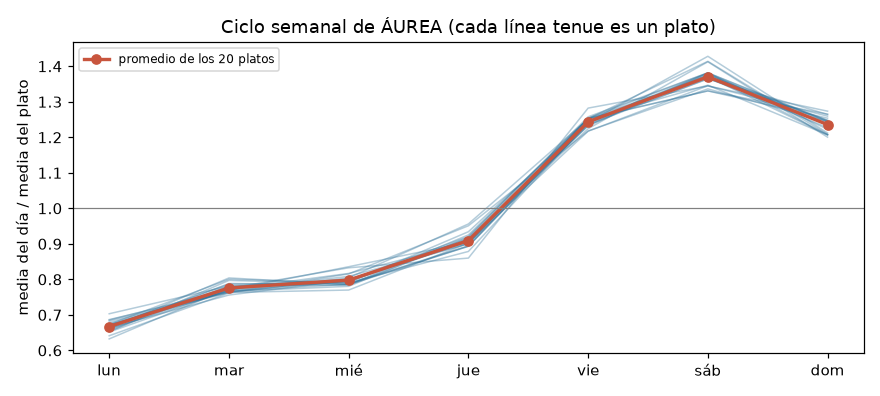

,lun,mar,mié,jue,vie,sáb,dom
plato,,,,,,,
Agua Mineral 625ml,0.69,0.77,0.78,0.92,1.25,1.37,1.23
Ají de Gallina,0.70,0.78,0.78,0.93,1.25,1.35,1.21
Arroz con Mariscos,0.66,0.78,0.80,0.91,1.23,1.38,1.24
Causa Limeña de Pollo,0.63,0.77,0.83,0.86,1.28,1.34,1.27
Cerveza Cusqueña,0.66,0.76,0.80,0.92,1.26,1.38,1.22
Ceviche Clásico,0.66,0.79,0.78,0.89,1.25,1.41,1.21


In [12]:
abiertos = abiertos.assign(dow=abiertos.fecha.dt.day_of_week)
ciclo = abiertos.pivot_table(index="plato", columns="dow", values="unidades", aggfunc="mean")
ciclo = ciclo.div(ciclo.mean(axis=1), axis=0); ciclo.columns = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(ciclo.columns, ciclo.T.values, color="#2a6f97", alpha=.35, lw=1)
ax.plot(ciclo.columns, ciclo.mean().values, color="#c8553d", lw=2.2, marker="o", label="promedio de los 20 platos")
ax.axhline(1, color="grey", lw=.8); ax.set_ylabel("media del día / media del plato")
ax.set_title("Ciclo semanal de ÁUREA (cada línea tenue es un plato)"); ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(FIGURAS / "aurea_ciclo_semanal.png", dpi=110); plt.close(fig); display(Image(FIGURAS / "aurea_ciclo_semanal.png"))
ciclo.round(2).head(6)

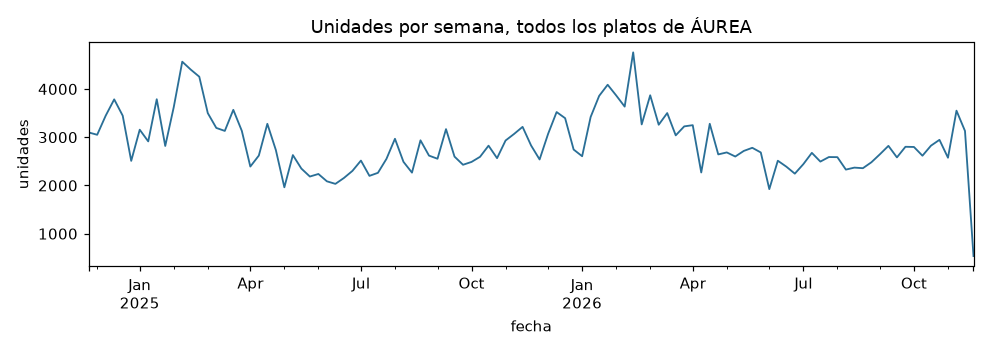

In [13]:
semanal = abiertos.groupby([pd.Grouper(key="fecha", freq="W")]).unidades.sum()
fig, ax = plt.subplots(figsize=(9, 3.2)); semanal.plot(ax=ax, lw=1.2, color="#2a6f97")
ax.set_title("Unidades por semana, todos los platos de ÁUREA"); ax.set_ylabel("unidades"); fig.tight_layout()
fig.savefig(FIGURAS / "aurea_serie_semanal.png", dpi=110); plt.close(fig); display(Image(FIGURAS / "aurea_serie_semanal.png"))

In [14]:
# Navidad y Año Nuevo: ventas totales del local alrededor de los cierres
navidad = total_dia[(total_dia.index >= "2024-12-20") & (total_dia.index <= "2025-01-03")].to_frame("total_unidades")
navidad["cerrado"] = navidad.index.isin(cerrados); navidad.T

fecha,2024-12-20,2024-12-21,2024-12-22,2024-12-23,2024-12-24,2024-12-25,2024-12-26,2024-12-27,2024-12-28,2024-12-29,2024-12-30,2024-12-31,2025-01-01,2025-01-02,2025-01-03
total_unidades,830,631,631,205,218,0,353,459,610,665,298,189,0,441,712
cerrado,False,False,False,False,False,True,False,False,False,False,False,False,True,False,False


## 8. Salidas

In [15]:
historial.to_parquet(SALIDA / "historial.parquet", index=False)
(SALIDA / "calendario.json").write_text(json.dumps({**calendario, **meta}, indent=1, ensure_ascii=False), encoding="utf-8")
(SALIDA / "productos.json").write_text(json.dumps(nombres, indent=1, ensure_ascii=False), encoding="utf-8")
sorted(p.name for p in SALIDA.iterdir())

['calendario.json',
 'feriados_generador.json',
 'historial.parquet',
 'productos.json',
 'verdad.parquet']

## Verificaciones

In [16]:
assert sin_firma == 401 and firma_ajena == 401, "ms-analitica debe rechazar peticiones sin firma o con firma ajena"
assert demasiado.status_code == 422 and demasiado.json()["errores"][0]["codigo"] == "ERR_RANGO_INVALIDO"
assert list(tramos(DESDE, HASTA)) == [(DESDE, HASTA)]
assert list(tramos(date(2024, 1, 1), date(2028, 1, 9)))[0][1] == date(2024, 1, 1) + timedelta(days=729)
assert historial.producto_id.nunique() == 20 and len(historial) == 20 * 730, historial.shape
assert (historial.groupby("producto_id").size() == 730).all()
assert historial.fecha.max() < pd.Timestamp.today().normalize()
assert cerrados.equals(esperados), "la regla de respaldo no detecto exactamente el 25/12 y el 01/01 de cada ano"
assert evento_posterior and meta["ultimo_evento_en_confiable"] is False
assert len(verdad) == 20 * 730 and len(m) == len(historial), "la demanda verdadera no cubre la serie"
assert set(calendario["dias_cerrados"]) == {str(d.date()) for d in esperados}
assert historial.unidades.ge(0).all()
print("OK · ÁUREA coherente con el contrato (D-23 verificada)")

OK · ÁUREA coherente con el contrato (D-23 verificada)
